# Exp 5 – Strongly Regularized Model | XGBoost Classifier

1. One-Hot Encoding (OHE) is applied to categorical features.
2. Class imbalance is handled using scale_pos_weight, calculated from the model training data.
3. The original training data is split into model training (80%) and validation (20%), keeping the test set untouched.
4. RandomizedSearchCV with 5-Fold Stratified CV and 40 iterations is used to find the best XGBoost hyperparameters based on PR-AUC.
5. Strong regularization is applied through restricted tree depth, subsampling, min_child_weight, gamma, L1, and L2 penalties.
6. The best model generates churn probabilities on the validation set.
7. Validation probabilities are used to select the best classification threshold based on F1 Score.
8. The selected threshold is applied to training, validation, and test probabilities to generate:
   0 = Retained | 1 = Churned.
9. Model performance is evaluated using classification metrics, confusion matrix, and cross-validation.
10. Feature importance is analysed to identify the most influential features.

### 0. IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

### 1. SEPARATE FEATURES AND TARGET

In [3]:
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total missing values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

Total missing values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.284814
1     9.715186
Name: proportion, dtype: float64


### 2. ORIGINAL TRAIN TEST SPLIT

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)


Original Training Data: (11684, 104)
Original Test Data: (2922, 104)


### 3. INTERNAL TRAIN VALIDATION SPLIT

In [5]:
# Keep original test data untouched.
# Use validation data for threshold selection.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)


Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)


### 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS

In [6]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))


Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101


### 5. CLASS IMBALANCE

In [7]:
negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()
scale_pos_weight_value = negative_count / positive_count

print("\n==== CLASS IMBALANCE ====")
print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", scale_pos_weight_value)


==== CLASS IMBALANCE ====
Negative Class: 8439
Positive Class: 908
Scale Pos Weight: 9.294052863436123


### 6. PREPROCESSING PIPELINE

In [8]:
categorical_pipeline = OneHotEncoder(handle_unknown='ignore')

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=1
)

### 7. STRONGLY REGULARIZED XGBOOST PIPELINE

In [9]:
xgb_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", XGBClassifier(
        objective='binary:logistic',
        eval_metric='aucpr',
        tree_method='hist',
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))
])

### 8. STRATIFIED CROSS VALIDATION

In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

### 9. STRONG REGULARIZATION SEARCH SPACE

In [11]:
param_grid = {
    # Number of boosting trees
    'model__n_estimators': [300, 500, 700, 900],

    # Restrict tree depth
    'model__max_depth': [2, 3, 4],

    # Lower learning rates
    'model__learning_rate': [0.01, 0.03, 0.05],

    # Row subsampling
    'model__subsample': [0.6, 0.7, 0.8],

    # Feature subsampling
    'model__colsample_bytree': [0.5, 0.6, 0.7],

    # Stronger minimum child weight
    'model__min_child_weight': [5, 10, 15, 20],

    # Stronger split restrictions
    'model__gamma': [0.3, 0.5, 1, 2],

    # L1 regularization
    'model__reg_alpha': [0.1, 1, 5, 10],

    # L2 regularization
    'model__reg_lambda': [5, 10, 20, 50],

    # Class imbalance
    'model__scale_pos_weight': [
        1,
        scale_pos_weight_value * 0.25,
        scale_pos_weight_value * 0.50,
        scale_pos_weight_value * 0.75,
        scale_pos_weight_value
    ]
}

### 10. RANDOMIZED SEARCH CV

In [12]:
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=40,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

### 11. FIT RANDOMIZED SEARCH

In [13]:
random_search.fit(X_fit, y_fit)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'model__colsample_bytree': [0.5, 0.6, ...], 'model__gamma': [0.3, 0.5, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [2, 3, ...], ...}"
,n_iter,40
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


### 12. BEST HYPERPARAMETERS

In [14]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:")
print(random_search.best_score_)


==== BEST HYPERPARAMETERS ====
{'model__subsample': 0.8, 'model__scale_pos_weight': np.float64(4.647026431718062), 'model__reg_lambda': 50, 'model__reg_alpha': 1, 'model__n_estimators': 900, 'model__min_child_weight': 10, 'model__max_depth': 4, 'model__learning_rate': 0.03, 'model__gamma': 2, 'model__colsample_bytree': 0.6}

Best CV PR-AUC:
0.2638356437360839


### 13. BEST XGBOOST MODEL

In [15]:
best_xgb_pipeline = random_search.best_estimator_

### 14. RANDOMIZED SEARCH RESULTS

In [16]:
search_results_df = pd.DataFrame(random_search.cv_results_)

search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")

display_cols = [
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__learning_rate',
    'param_model__min_child_weight',
    'param_model__gamma',
    'param_model__reg_alpha',
    'param_model__reg_lambda',
    'param_model__scale_pos_weight',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]

print(
    search_results_df[display_cols]
    .head(10)
    .round(4)
    .to_string(index=False)
)


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators  param_model__max_depth  param_model__learning_rate  param_model__min_child_weight  param_model__gamma  param_model__reg_alpha  param_model__reg_lambda  param_model__scale_pos_weight  mean_train_score  mean_test_score  std_test_score
                       900                       4                        0.03                             10                 2.0                     1.0                       50                         4.6470            0.7990           0.2638          0.0238
                       700                       3                        0.05                             20                 0.5                     0.1                       10                         2.3235            0.6931           0.2567          0.0254
                       700                       4                        0.05                             20                 1.0                     5.0                  

### 15. VALIDATION PROBABILITIES

In [17]:
y_prob_val = best_xgb_pipeline.predict_proba(X_val)[:, 1]

### 16. PRECISION RECALL CURVE

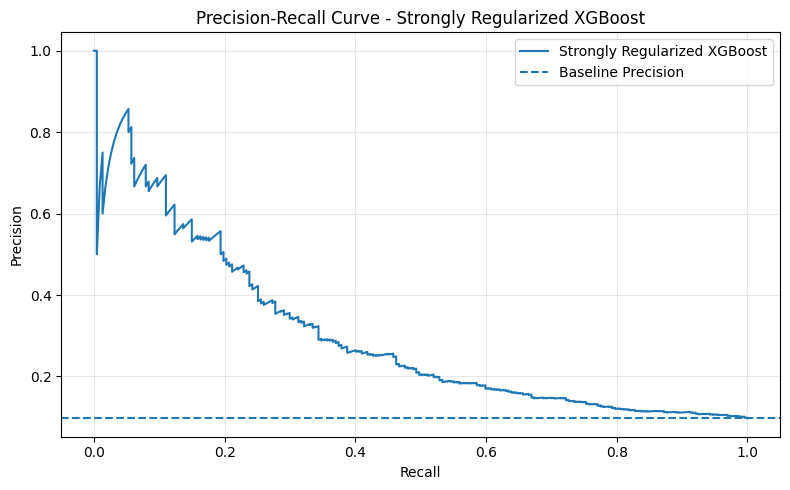

In [18]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='Strongly Regularized XGBoost'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Strongly Regularized XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 17. FINE-GRAINED THRESHOLD ANALYSIS

In [19]:
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    precision_value = precision_score(
        y_val, y_pred,
        zero_division=0
    )
    recall_value = recall_score(
        y_val, y_pred,
        zero_division=0
    )
    f1_value = f1_score(
        y_val, y_pred,
        zero_division=0
    )

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_value,
        'Recall': recall_value,
        'F1 Score': f1_value
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1008  0.9956    0.1831
      0.06     0.1016  0.9868    0.1843
      0.07     0.1029  0.9736    0.1862
      0.08     0.1053  0.9692    0.1900
      0.09     0.1064  0.9515    0.1914
      0.10     0.1073  0.9251    0.1923
      0.11     0.1108  0.9163    0.1977
      0.12     0.1130  0.8899    0.2006
      0.13     0.1148  0.8722    0.2030
      0.14     0.1155  0.8370    0.2030
      0.15     0.1189  0.8194    0.2077
      0.16     0.1220  0.7974    0.2117
      0.17     0.1259  0.7885    0.2171
      0.18     0.1287  0.7709    0.2205
      0.19     0.1338  0.7533    0.2272
      0.20     0.1381  0.7357    0.2326
      0.21     0.1437  0.7225    0.2398
      0.22     0.1470  0.7004    0.2429
      0.23     0.1483  0.6740    0.2431
      0.24     0.1557  0.6652    0.2523
      0.25     0.1597  0.6432    0.2559
      0.26     0.1663  0.6300    0.2631
      0.27     0.1710  0.6079    0.26

### 18. THRESHOLD PERFORMANCE VISUALIZATION

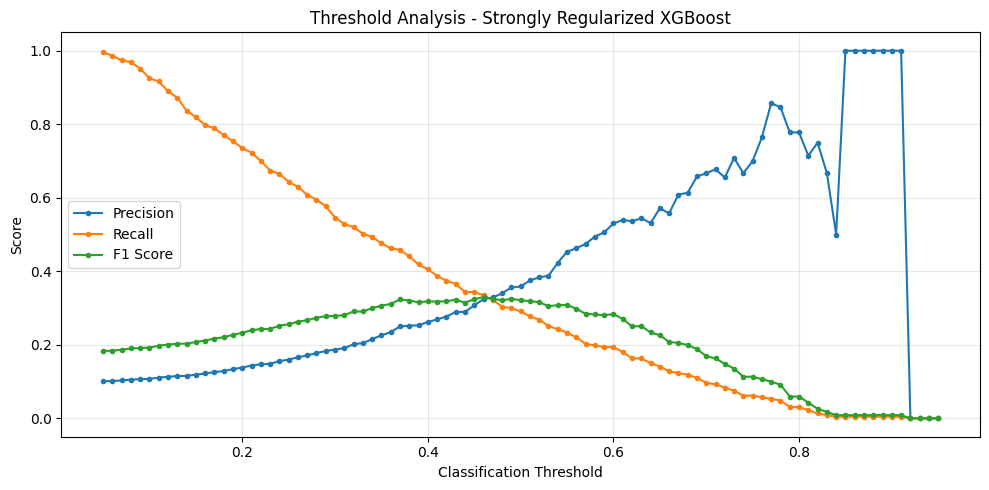

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Strongly Regularized XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 19. SELECT BEST THRESHOLD

In [21]:
best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()
best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)
print(fine_threshold_df.loc[best_threshold_idx])


==== BEST THRESHOLD ====
Best Threshold: 0.4600000000000001
Threshold    0.460000
Precision    0.324786
Recall       0.334802
F1 Score     0.329718
Name: 41, dtype: float64


### 20. DEFINE METRIC FUNCTION

In [22]:
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

### 21. TRAINING PREDICTIONS

In [23]:
y_prob_train = best_xgb_pipeline.predict_proba(X_fit)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

### 22. VALIDATION PREDICTIONS

In [24]:
y_pred_val = (y_prob_val >= best_threshold).astype(int)

### 23. TEST PREDICTIONS

In [25]:
y_prob_test = best_xgb_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

### 24. CALCULATE METRICS

In [26]:
train_metrics = calc_metrics(
    y_fit, y_pred_train, y_prob_train
)

validation_metrics = calc_metrics(
    y_val, y_pred_val, y_prob_val
)

test_metrics = calc_metrics(
    y_test, y_pred_test, y_prob_test
)

### 25. PRINT TRAIN METRICS

In [27]:
print("\n==== TRAIN METRICS ====")

for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.9330
Precision   : 0.6353
Recall      : 0.7291
F1 Score    : 0.6790
ROC-AUC     : 0.9562
PR-AUC      : 0.7533


### 26. PRINT VALIDATION METRICS

In [28]:
print("\n==== VALIDATION METRICS ====")

for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== VALIDATION METRICS ====
Accuracy    : 0.8678
Precision   : 0.3248
Recall      : 0.3348
F1 Score    : 0.3297
ROC-AUC     : 0.6990
PR-AUC      : 0.2991


### 27. PRINT TEST METRICS

In [29]:
print("\n==== TEST METRICS ====")

for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TEST METRICS ====
Accuracy    : 0.8669
Precision   : 0.3183
Recall      : 0.3239
F1 Score    : 0.3211
ROC-AUC     : 0.6958
PR-AUC      : 0.2942


### 28. CONFUSION MATRIX

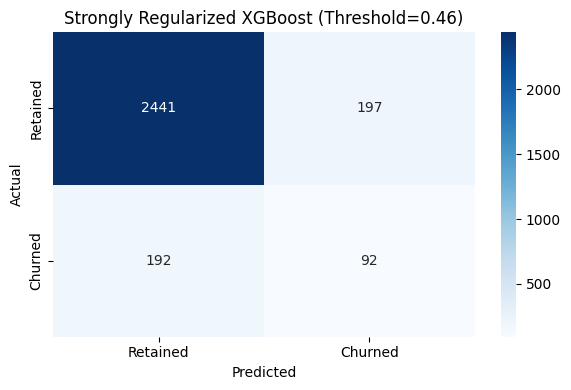

In [30]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Strongly Regularized XGBoost '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

### 29. CLASSIFICATION REPORT

In [31]:
print("\n==== CLASSIFICATION REPORT ====")

print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.93      0.93      2638
     Churned       0.32      0.32      0.32       284

    accuracy                           0.87      2922
   macro avg       0.62      0.62      0.62      2922
weighted avg       0.87      0.87      0.87      2922



### 30. CROSS VALIDATION PERFORMANCE

In [32]:
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_xgb_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

### 31. CROSS VALIDATION TRAIN SCORES

In [33]:
print("\n==== CROSS VALIDATION TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9472, Std: 0.0015
train_Precision - Mean: 0.7391, Std: 0.0097
train_Recall - Mean: 0.7062, Std: 0.0143
train_F1 - Mean: 0.7222, Std: 0.0090
train_ROC_AUC - Mean: 0.9671, Std: 0.0017
train_PR_AUC - Mean: 0.7990, Std: 0.0095


### 32. CROSS VALIDATION VALIDATION SCORES

In [34]:
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.8794, Std: 0.0041
test_Precision - Mean: 0.3346, Std: 0.0305
test_Recall - Mean: 0.2456, Std: 0.0312
test_F1 - Mean: 0.2830, Std: 0.0310
test_ROC_AUC - Mean: 0.6874, Std: 0.0193
test_PR_AUC - Mean: 0.2638, Std: 0.0238


### 33. FEATURE IMPORTANCE

In [35]:
xgb_model = best_xgb_pipeline.named_steps['model']

feature_names = (
    best_xgb_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20))


==== TOP 20 IMPORTANT FEATURES ====
                                           Feature  Importance
0       origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws    0.028995
1       origin_up_lxidpiddsbxsbosboudacockeimpuepw    0.024446
2                                           tenure    0.015970
3                               margin_net_pow_ele    0.015706
4                 discount_consumption_interaction    0.014973
5   channel_sales_lmkebamcaaclubfxadlmueccxoimlema    0.014958
6                          var_year_price_peak_fix    0.014476
7                                    renewal_month    0.012465
8                        dec_jan_mid_peak_fix_diff    0.012456
9                                  num_years_antig    0.012205
10                           dec_jan_peak_fix_diff    0.011616
11                                       has_gas_t    0.011381
12                     var_year_price_mid_peak_fix    0.011091
13                                    months_activ    0.010909
14                

### 34. FEATURE IMPORTANCE VISUALIZATION

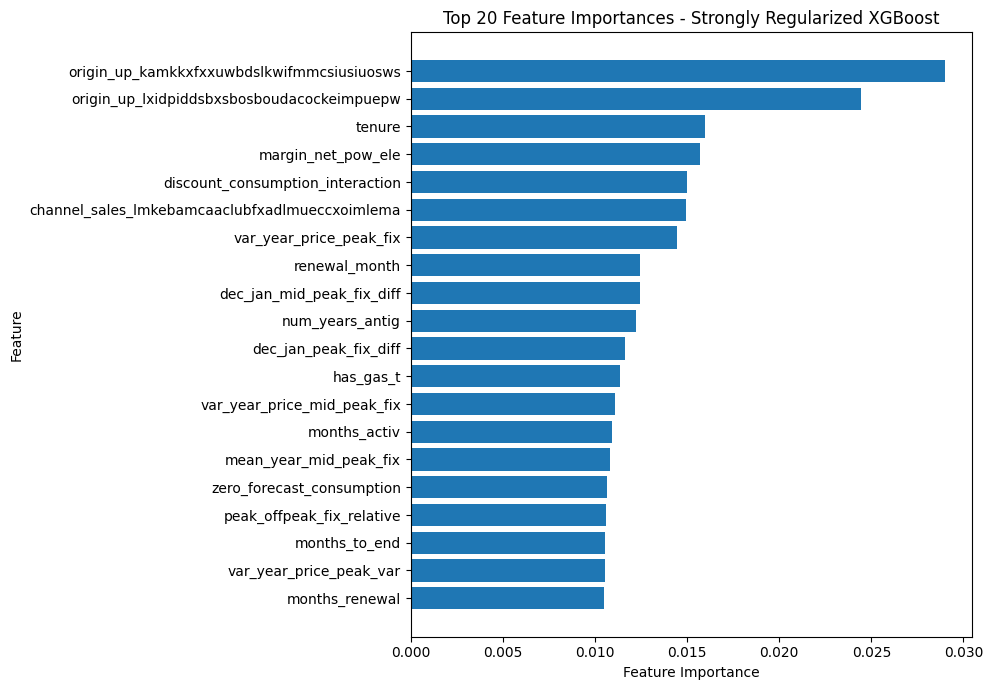

In [36]:
top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Strongly Regularized XGBoost')
plt.tight_layout()
plt.show()

# **Observation: Exp 5 – Strongly Regularized Model | XGBoost Classifier**

**1. Model Optimization**

- Applied stronger regularization using 40 hyperparameter combinations and 5-fold cross-validation.
- Class imbalance was considered using `scale_pos_weight`.
- Best hyperparameters:
  - `n_estimators`: 900
  - `max_depth`: 4
  - `learning_rate`: 0.03
  - `subsample`: 0.8
  - `colsample_bytree`: 0.6
  - `min_child_weight`: 10
  - `gamma`: 2
  - `reg_alpha`: 1
  - `reg_lambda`: 50
  - `scale_pos_weight`: 4.65
- Best CV PR-AUC: **26.38%**

**Observation:**

- Stronger regularization reduced model complexity.
- Training-validation performance gap decreased compared to Exp4.
- However, CV PR-AUC decreased from 28.42% to 26.38%.

**2. Model Performance – Test Data**

- Accuracy: **86.69%**
- Precision: **31.83%**
- Recall: **32.39%**
- F1 Score: **32.11%**
- ROC-AUC: **69.58%**
- PR-AUC: **29.42%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.46**, based on the highest F1 score in the threshold analysis.
- At threshold 0.46 (threshold validation):
  - Precision: 32.48%
  - Recall: 33.48%
  - F1 Score: 32.97%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.46)**

- True Negatives: 2,441
- False Positives: 197
- False Negatives: 192
- True Positives: 92

**Observation:**

- Model correctly identifies 92 churn customers out of 284.
- It misses 192 actual churn customers.
- False positives are relatively low, but churn identification remains limited.

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 29.42% is lower than Exp4 XGBoost (32.15%).

**6. Cross-Validation Results**

- Training PR-AUC: 79.90%
- Validation accuracy: 87.94%
- Validation precision: 33.46%
- Validation recall: 24.56%
- Validation F1: 28.30%
- Validation ROC-AUC: 68.74%
- Validation PR-AUC: 26.38%

**Observation:**

- Training-validation performance gap has reduced compared to Exp4.
- Validation recall remains low.
- Stronger regularization reduced overfitting but did not improve validation PR-AUC.

**7. Top 20 Important Features**

The most important features include:

- origin_up related features
- tenure
- margin_net_pow_ele
- discount_consumption_interaction
- channel_sales related feature
- var_year_price_peak_fix
- renewal_month
- dec_jan_mid_peak_fix_diff
- num_years_antig

**Observation:**

- Subscription-related features, customer tenure and pricing-related features contribute significantly.
- `origin_up` features have the highest importance.

**8. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 |
| Recall    | 36.97%           | 34.86%              | **38.73%**            | 28.52%       | 32.39%                 |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 |

**Observation:**

- Strongly Regularized XGBoost reduces the training-validation performance gap.
- However, test PR-AUC decreases to 29.42%.
- Precision, recall and F1 Score are also lower than Exp4.
- Stronger regularization has not improved overall churn prediction performance.

**Final Conclusion – Strongly Regularized XGBoost**

- Stronger regularization helped control overfitting.
- However, test PR-AUC decreased from 32.15% to 29.42%.
- The model does not provide better churn identification than Exp4.
- Stronger regularization did not improve overall model performance.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Regularized Random Forest remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%). Exp4 XGBoost provides higher precision (43.09%), but Exp2 offers a better overall balance between precision and recall.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.46 threshold. Compare classification metrics cautiously.